







#Sinh viên thực hiện: Mssv
#Tô Thành Nhân       3124411198
#Trần Lê Gia Bảo     3124411038
#Nguyễn Thanh Tuấn   3124411337
#Đào Hữu Tài         3124411261
#Huỳnh Nhật Quang    3124411245

Tháng 10 năm 2026

## Mục lục
1. [Giới thiệu & dữ liệu](#1.-Giới-thiệu-&-dữ-liệu)
2. [Tiền xử lý dữ liệu](#2.-Tiền-xử-lý-dữ-liệu)
3. [Feature Selection & đánh giá mô hình](#3.-Feature-Selection-&-đánh-giá-mô-hình)
4. [Biểu đồ kết quả](#4.-Biểu-đồ-kết-quả)
5. [Tổng hợp & kết luận](#5.-Tổng-hợp-&-kết-luận)

> **Cách chạy:** đặt `data.csv` cùng thư mục với notebook (trên Colab: tải file lên ở thanh bên trái) rồi chọn *Run all* (~5–6 phút). Cell đầu cài thư viện nếu thiếu.

# 1. Giới thiệu & dữ liệu
**Mục tiêu:** (i) chọn dataset House Price Prediction; (ii) tiền xử lý; (iii) so sánh các kỹ thuật Feature Selection (Filter / Embedded / Wrapper) với SVM, XGBoost, Random Forest.

**Dataset:** `data.csv` – 4.600 giao dịch bán nhà tại bang Washington (Seattle), năm 2014, 18 cột; biến mục tiêu là `price`.
(`output.csv` khác `data.csv` đúng 2 dòng có `sqft_living` sai nên không dùng; `data.dat` là bản JSON lồng nhau của cùng dữ liệu, khớp 4.375/4.601 bản ghi, không dùng.)

In [1]:
# Cài thư viện nếu thiếu (Colab/máy mới). xgboost là tuỳ chọn: nếu không có, notebook dùng gradient boosting của sklearn (nhãn 'XGBoost*').
import importlib, subprocess, sys, os
for pkg in ["numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "xgboost"]:
    mod = "sklearn" if pkg == "scikit-learn" else pkg
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
os.makedirs("results", exist_ok=True); os.makedirs("figures", exist_ok=True)
%matplotlib inline

# 2. Tiền xử lý dữ liệu
Làm sạch (giá = 0, số phòng = 0), loại ngoại lai 3×IQR, xây dựng đặc trưng (tuổi nhà, cờ cải tạo, zipcode, tỉ số, log diện tích đất, one-hot thành phố), mã hoá lại `yr_renovated`, và vẽ biểu đồ EDA.

In [2]:
import json, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SRC = "data.csv"   # đường dẫn tới file dữ liệu
log = {}
df = pd.read_csv(SRC)
log["raw_shape"] = list(df.shape)
log["missing_cells"] = int(df.isna().sum().sum())
log["duplicates"] = int(df.duplicated().sum())

### 1. Loai ban ghi khong hop le

In [3]:
# ---- 1. Loai ban ghi khong hop le -------------------------------------------------
n0 = len(df)
df = df[df.price > 0]                                   # gia = 0 la gia tri thieu
log["drop_price_zero"] = n0 - len(df); n1 = len(df)
df = df[(df.bedrooms > 0) & (df.bathrooms > 0)]         # nha khong phong ngu / phong tam
log["drop_zero_rooms"] = n1 - len(df); n2 = len(df)
df = df.drop_duplicates()
log["drop_duplicates"] = n2 - len(df)

### 2. Loai ngoai lai (outlier)

In [4]:
# ---- 2. Loai ngoai lai (outlier) -------------------------------------------------
# IQR*3 tren log(price) va sqft_living / sqft_lot (cac gia tri cuc doan, vd nha 26.5 trieu USD)
def iqr_mask(s, k=3.0):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s >= q1 - k * i) & (s <= q3 + k * i)
n3 = len(df)
m = iqr_mask(np.log1p(df.price)) & iqr_mask(df.sqft_living) & iqr_mask(np.log1p(df.sqft_lot))
df = df[m]
log["drop_outliers"] = n3 - len(df)

### 3. Feature engineering

In [5]:
# ---- 3. Feature engineering ------------------------------------------------------
d = pd.to_datetime(df.date)
df["sale_year"] = d.dt.year
df["sale_month"] = d.dt.month
df["was_renovated"] = (df.yr_renovated > 0).astype(int)          # 0 = chua tung cai tao (khong phai nam 0)
last = np.where(df.yr_renovated > 0, df.yr_renovated, df.yr_built)
df["house_age"] = df.sale_year - df.yr_built
df["years_since_reno"] = df.sale_year - last
df["has_basement"] = (df.sqft_basement > 0).astype(int)
df["zipcode"] = df.statezip.str.extract(r"(\d{5})")[0].astype(int)
df["bath_per_bed"] = df.bathrooms / df.bedrooms
df["living_lot_ratio"] = df.sqft_living / df.sqft_lot
df["log_sqft_lot"] = np.log1p(df.sqft_lot)
# Bo cot: street (dinh danh), country (hang so), statezip (da tach zipcode), date, yr_renovated (da ma hoa), sqft_lot (da log)
df = df.drop(columns=["date", "street", "country", "statezip", "yr_renovated", "sqft_lot"])
# city: giu 15 thanh pho pho bien nhat, con lai gom 'Other' roi one-hot
top = df.city.value_counts().head(15).index
df["city"] = df.city.where(df.city.isin(top), "Other")
df = pd.get_dummies(df, columns=["city"], prefix="city", dtype=int)
log["final_shape"] = list(df.shape)
log["n_features"] = df.shape[1] - 1
log["features"] = [c for c in df.columns if c != "price"]
df = df.reset_index(drop=True)
df.to_csv("results/clean.csv", index=False)
json.dump(log, open("results/preprocess_log.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps({k: v for k, v in log.items() if k != "features"}, indent=1))

{
 "raw_shape": [
  4600,
  18
 ],
 "missing_cells": 0,
 "duplicates": 0,
 "drop_price_zero": 49,
 "drop_zero_rooms": 2,
 "drop_duplicates": 0,
 "drop_outliers": 94,
 "final_shape": [
  4455,
  37
 ],
 "n_features": 36
}


### 4. Hinh EDA

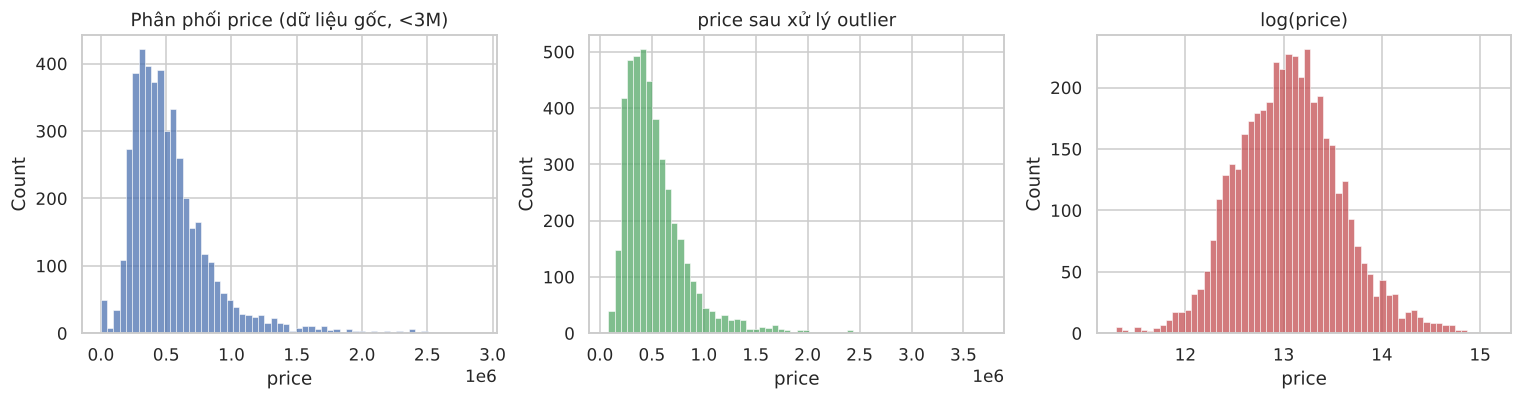

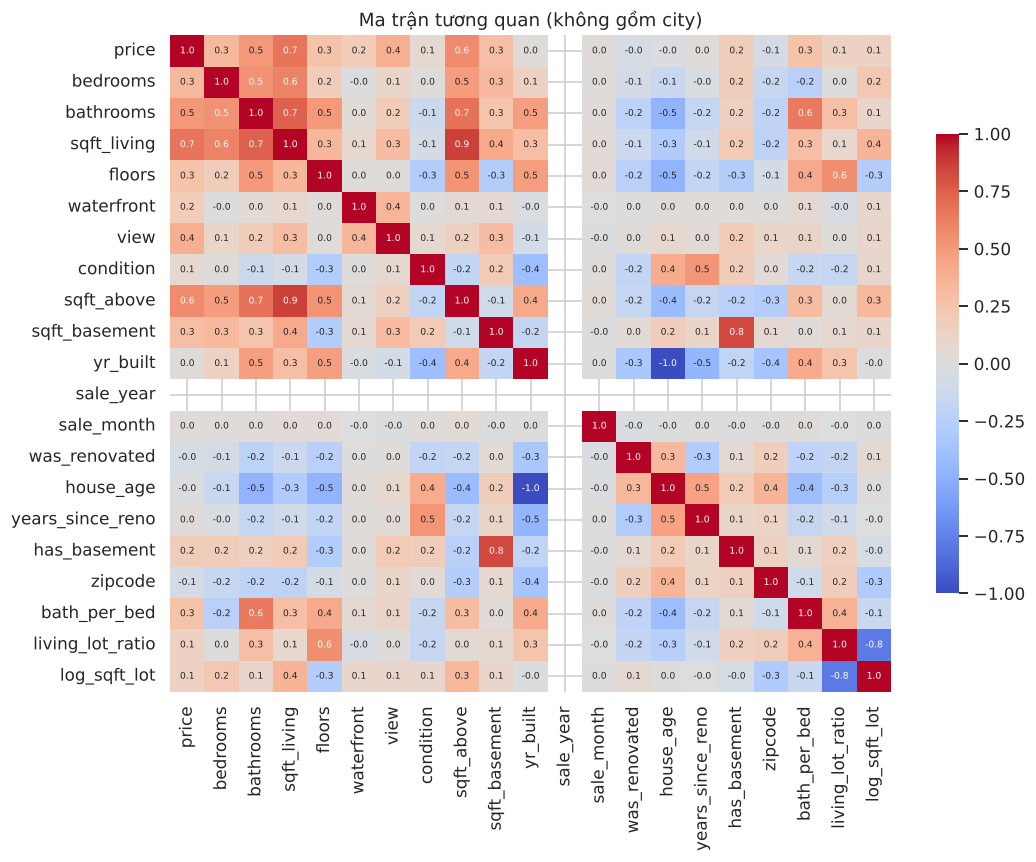

In [6]:
# ---- 4. Hinh EDA -----------------------------------------------------------------
sns.set_theme(style="whitegrid")
raw = pd.read_csv(SRC)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(raw.price[raw.price < 3e6], bins=60, ax=ax[0], color="#4C72B0"); ax[0].set_title("Phân phối price (dữ liệu gốc, <3M)")
sns.histplot(df.price, bins=60, ax=ax[1], color="#55A868"); ax[1].set_title("price sau xử lý outlier")
sns.histplot(np.log(df.price), bins=60, ax=ax[2], color="#C44E52"); ax[2].set_title("log(price)")
plt.tight_layout(); plt.savefig("figures/fig1_price_dist.png", dpi=160); plt.show()

num = [c for c in df.columns if not c.startswith("city_")]
plt.figure(figsize=(10, 8)); sns.heatmap(df[num].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 6}, cbar_kws={"shrink": .7})
plt.title("Ma trận tương quan (không gồm city)"); plt.tight_layout(); plt.savefig("figures/fig2_corr.png", dpi=160); plt.show()

# 3. Feature Selection & đánh giá mô hình
- **8 cấu hình**, mỗi cấu hình chọn *k = 15* trong 36 đặc trưng: Baseline (all), Pearson F-test, Mutual Info *(Filter)*; Lasso, RF importance, XGBoost importance *(Embedded)*; RFE (RF), Forward SFS-Ridge *(Wrapper)*.
- **3 mô hình:** SVM (SVR, RBF), XGBoost, Random Forest.
- **Quy trình:** chia 80/20; FS chỉ fit trên train (và fit lại trong từng fold của CV 5-fold ⇒ không rò rỉ dữ liệu); mục tiêu log(price), chỉ số tính trên thang USD.
- ⚠️ Nếu không có thư viện `xgboost`, mô hình gradient boosting được thay bằng `HistGradientBoostingRegressor` và gắn nhãn **XGBoost\***.

In [7]:
import time, json, warnings
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LassoCV, Ridge, LinearRegression
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression, RFE, SequentialFeatureSelector
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings("ignore")
SEED, K = 42, 15

try:
    from xgboost import XGBRegressor
    XGB_NAME = "XGBoost"
    def make_xgb(): return XGBRegressor(n_estimators=400, learning_rate=.05, max_depth=5, subsample=.8, colsample_bytree=.8, n_jobs=2, random_state=SEED)
    def make_xgb_imp(): return XGBRegressor(n_estimators=150, learning_rate=.1, max_depth=4, n_jobs=2, random_state=SEED)
except ImportError:   # moi truong khong cai duoc xgboost -> dung gradient boosting cung ho cay (sklearn)
    XGB_NAME = "XGBoost*"
    def make_xgb(): return HistGradientBoostingRegressor(max_iter=400, learning_rate=.05, max_depth=5, random_state=SEED)
    def make_xgb_imp(): return GradientBoostingRegressor(n_estimators=150, learning_rate=.1, max_depth=4, random_state=SEED)

MODELS = {
    "SVM": lambda: make_pipeline(StandardScaler(), SVR(C=3, epsilon=.05, gamma="scale")),
    XGB_NAME: make_xgb,
    "RandomForest": lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=2, max_features=.5, n_jobs=2, random_state=SEED),
}

### Cac ky thuat Feature Selection: ham (Xtr, ytr, k) -> danh sach cot

In [8]:
# ---------------- Cac ky thuat Feature Selection: ham (Xtr, ytr, k) -> danh sach cot ----------------
def top(scores, cols, k): return list(pd.Series(scores, index=cols).nlargest(k).index)
def fs_all(X, y, k): return list(X.columns)
def fs_pearson(X, y, k): return top(np.nan_to_num(f_regression(X, y)[0]), X.columns, k)
def fs_mi(X, y, k): return top(mutual_info_regression(X, y, random_state=SEED), X.columns, k)
def fs_lasso(X, y, k):
    Xs = StandardScaler().fit_transform(X); m = LassoCV(cv=5, random_state=SEED, max_iter=5000).fit(Xs, y)
    return top(np.abs(m.coef_), X.columns, k)
def fs_rf(X, y, k):
    m = RandomForestRegressor(200, min_samples_leaf=2, n_jobs=2, random_state=SEED).fit(X, y); return top(m.feature_importances_, X.columns, k)
def fs_xgb(X, y, k):
    m = make_xgb_imp().fit(X, y); return top(m.feature_importances_, X.columns, k)
def fs_rfe(X, y, k):
    r = RFE(RandomForestRegressor(100, min_samples_leaf=3, max_features=.5, n_jobs=2, random_state=SEED), n_features_to_select=k, step=3).fit(X, y)
    return list(X.columns[r.support_])
def fs_sfs(X, y, k):
    s = SequentialFeatureSelector(make_pipeline(StandardScaler(), Ridge(1.0)), n_features_to_select=k, direction="forward", cv=3, n_jobs=2).fit(X, y)
    return list(X.columns[s.get_support()])
FS = {  # ten: (ham, nhom)
    "Baseline (all)": (fs_all, "None"),
    "Pearson F-test": (fs_pearson, "Filter"), "Mutual Info": (fs_mi, "Filter"),
    "Lasso": (fs_lasso, "Embedded"), "RF importance": (fs_rf, "Embedded"), f"{XGB_NAME} importance": (fs_xgb, "Embedded"),
    "RFE (RF)": (fs_rfe, "Wrapper"), "Forward SFS (Ridge)": (fs_sfs, "Wrapper"),
}

def metrics(y_log, p_log):
    y, p = np.expm1(y_log), np.expm1(p_log)       # tinh tren thang gia goc (USD)
    return dict(R2=r2_score(y, p), RMSE=np.sqrt(mean_squared_error(y, p)), MAE=mean_absolute_error(y, p), R2_log=r2_score(y_log, p_log))

df = pd.read_csv("results/clean.csv")
X, y = df.drop(columns="price"), np.log1p(df.price)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=SEED)
Xtr, Xte, ytr, yte = [a.reset_index(drop=True) for a in (Xtr, Xte, ytr, yte)]
print("train", Xtr.shape, "test", Xte.shape, "| boosting model:", XGB_NAME)

def evaluate(fs_fn, Xa, ya, Xb, yb, k):
    t = time.time(); cols = fs_fn(Xa, ya, k); ft = time.time() - t
    out = {}
    for mn, mk in MODELS.items():
        t = time.time(); m = mk().fit(Xa[cols], ya); out[mn] = dict(metrics(yb, m.predict(Xb[cols])), fit_s=time.time() - t)
    return cols, ft, out

train (3564, 36) test (891, 36) | boosting model: XGBoost*


### (A) 5-fold CV tren tap train + (B) test hold-out

In [9]:
# ---------------- (A) 5-fold CV tren tap train + (B) test hold-out ----------------
rows, selected = [], {}
kf = KFold(5, shuffle=True, random_state=SEED)
for fname, (fn, grp) in FS.items():
    cv = {mn: [] for mn in MODELS}; fts = []
    for tr, va in kf.split(Xtr):
        _, ft, o = evaluate(fn, Xtr.iloc[tr], ytr.iloc[tr], Xtr.iloc[va], ytr.iloc[va], K)
        fts.append(ft)
        for mn in MODELS: cv[mn].append(o[mn])
    cols, ft, o = evaluate(fn, Xtr, ytr, Xte, yte, K); selected[fname] = cols
    for mn in MODELS:
        r = dict(Selector=fname, Group=grp, Model=mn, n_features=len(cols), select_time_s=ft, fit_time_s=o[mn]["fit_s"])
        for met in ("R2", "RMSE", "MAE"):
            v = [c[met] for c in cv[mn]]; r[f"CV_{met}"] = np.mean(v); r[f"CV_{met}_std"] = np.std(v); r[f"Test_{met}"] = o[mn][met]
        r["Test_R2_log"] = o[mn]["R2_log"]; rows.append(r)
    print(f"{fname:24s}", {mn: round(next(r for r in rows if r['Selector']==fname and r['Model']==mn)['Test_R2'], 4) for mn in MODELS}, flush=True)
res = pd.DataFrame(rows); res.to_csv("results/fs_results.csv", index=False)
json.dump(selected, open("results/selected_features.json", "w"), indent=1)

Baseline (all)           {'SVM': 0.6693, 'XGBoost*': 0.7373, 'RandomForest': 0.6866}
Pearson F-test           {'SVM': 0.6007, 'XGBoost*': 0.5814, 'RandomForest': 0.5622}
Mutual Info              {'SVM': 0.6374, 'XGBoost*': 0.7512, 'RandomForest': 0.6493}
Lasso                    {'SVM': 0.7299, 'XGBoost*': 0.7504, 'RandomForest': 0.6942}
RF importance            {'SVM': 0.6349, 'XGBoost*': 0.7404, 'RandomForest': 0.6634}
XGBoost* importance      {'SVM': 0.6997, 'XGBoost*': 0.7539, 'RandomForest': 0.6867}
RFE (RF)                 {'SVM': 0.6381, 'XGBoost*': 0.7572, 'RandomForest': 0.6537}
Forward SFS (Ridge)      {'SVM': 0.6378, 'XGBoost*': 0.6313, 'RandomForest': 0.6124}


### (C) Do nhay theo so dac trung k

In [10]:
# ---------------- (C) Do nhay theo so dac trung k ----------------
ks = [5, 8, 10, 15, 20, 25, 30, 36]
sens = []
for fname in ["Pearson F-test", "Mutual Info", "RF importance"]:
    fn = FS[fname][0]
    for k in ks:
        cols, _, o = evaluate(fn, Xtr, ytr, Xte, yte, k)
        for mn in MODELS: sens.append(dict(Selector=fname, k=k, Model=mn, Test_R2=o[mn]["R2"], Test_RMSE=o[mn]["RMSE"]))
    print("sens", fname, flush=True)
sens = pd.DataFrame(sens); sens.to_csv("results/k_sensitivity.csv", index=False)

print("done")

sens Pearson F-test
sens Mutual Info
sens RF importance
done


# 4. Biểu đồ kết quả

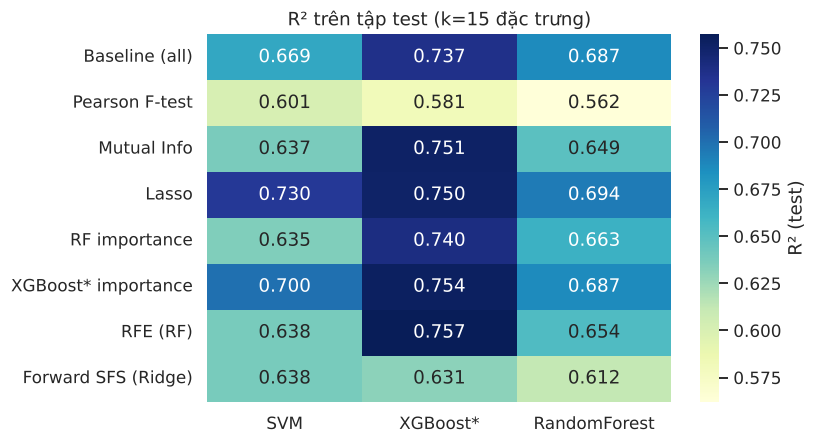

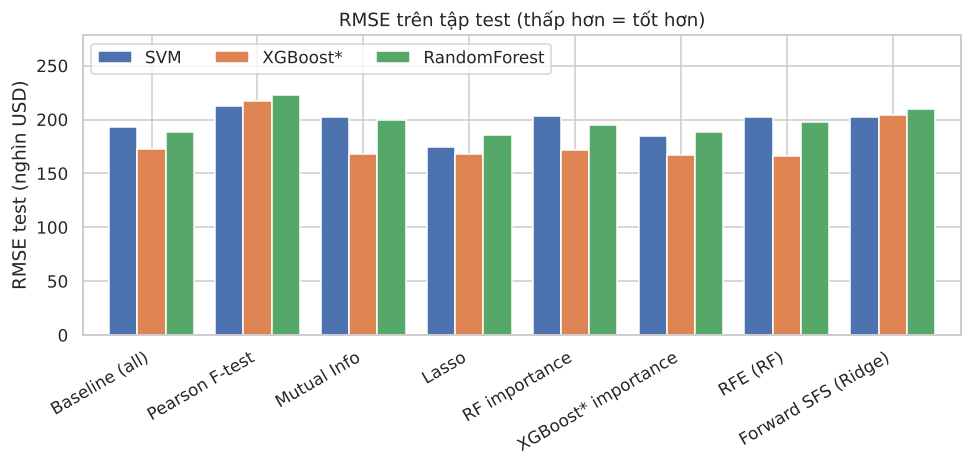

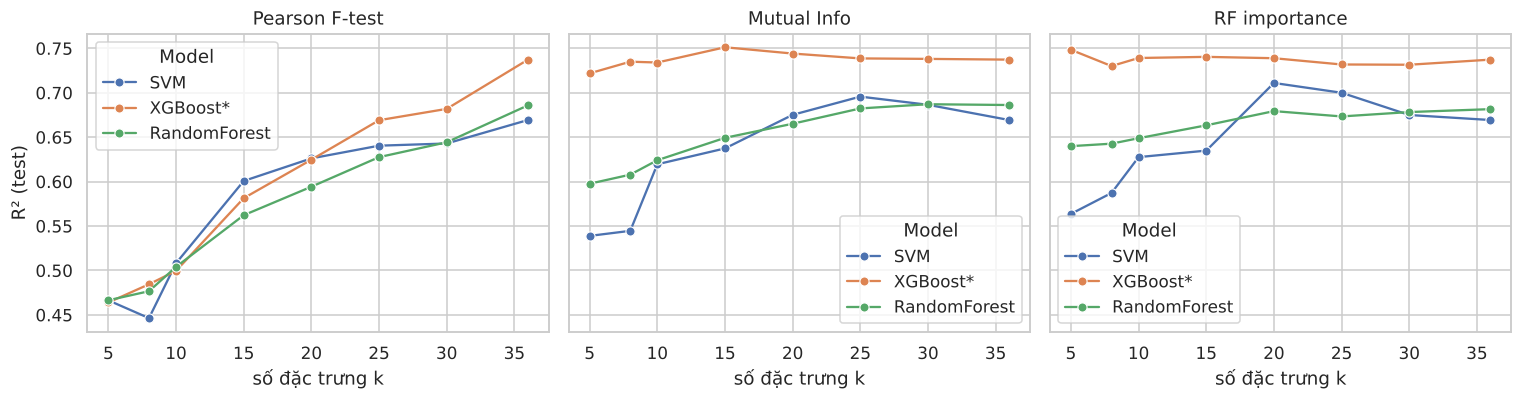

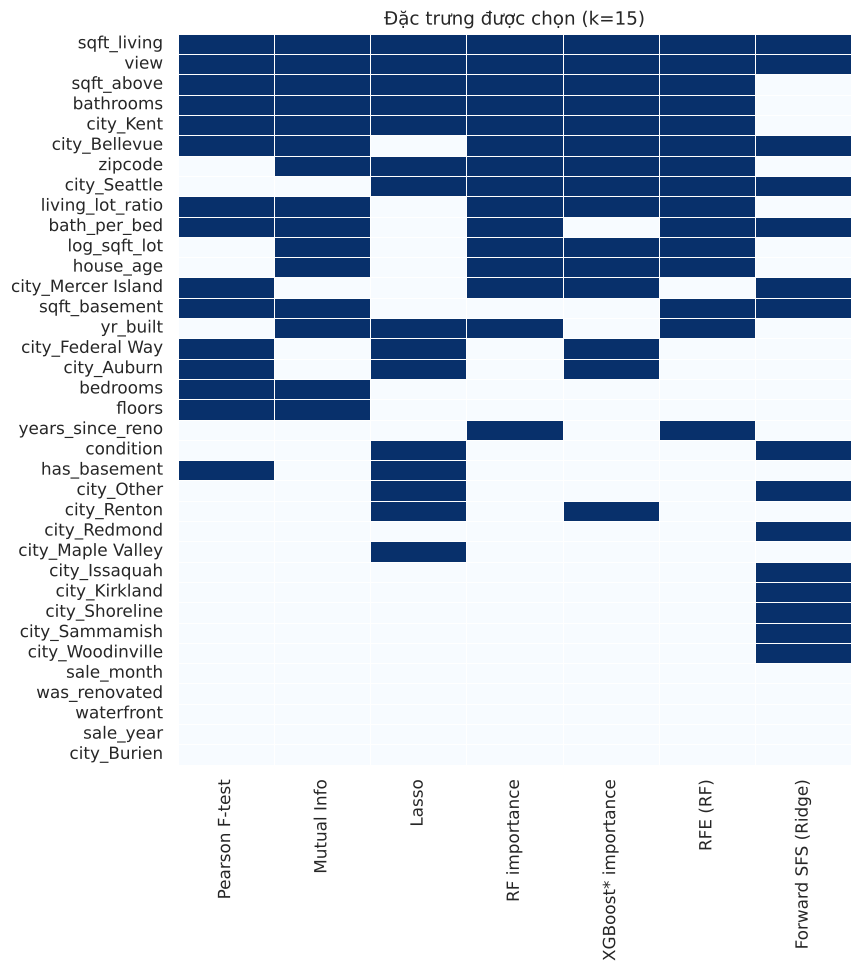

In [11]:
import json, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
res = pd.read_csv("results/fs_results.csv"); sens = pd.read_csv("results/k_sensitivity.csv")
sel_json = json.load(open("results/selected_features.json")); K = 15
order = list(dict.fromkeys(res.Selector)); models = list(dict.fromkeys(res.Model))
pv = res.pivot(index="Selector", columns="Model", values="Test_R2").loc[order][models]
plt.figure(figsize=(7.5, 4.2)); sns.heatmap(pv, annot=True, fmt=".3f", cmap="YlGnBu", cbar_kws={"label": "R² (test)"})
plt.title(f"R² trên tập test (k={K} đặc trưng)"); plt.ylabel(""); plt.xlabel(""); plt.tight_layout(); plt.savefig("figures/fig3_heatmap_r2.png", dpi=160); plt.show()
pr = (res.pivot(index="Selector", columns="Model", values="Test_RMSE").loc[order][models]) / 1000
ax = pr.plot.bar(figsize=(9, 4.4), width=.8); ax.set_ylabel("RMSE test (nghìn USD)"); ax.set_xlabel(""); ax.set_title("RMSE trên tập test (thấp hơn = tốt hơn)")
ax.set_ylim(0, pr.values.max() * 1.25); ax.legend(ncol=3, loc="upper left", title=None); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.savefig("figures/fig4_rmse.png", dpi=160); plt.show()
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, f in zip(axs, ["Pearson F-test", "Mutual Info", "RF importance"]):
    sns.lineplot(data=sens[sens.Selector == f], x="k", y="Test_R2", hue="Model", marker="o", ax=a); a.set_title(f); a.set_xlabel("số đặc trưng k"); a.set_ylabel("R² (test)")
plt.tight_layout(); plt.savefig("figures/fig5_k_sensitivity.png", dpi=160); plt.show()
feats = pd.read_csv("results/clean.csv", nrows=1).drop(columns="price").columns
sel = pd.DataFrame({f: pd.Series(1, index=c) for f, c in sel_json.items() if not f.startswith("Baseline")}).reindex(feats).fillna(0)
plt.figure(figsize=(8, 9)); sns.heatmap(sel.loc[sel.sum(1).sort_values(ascending=False).index], cmap="Blues", cbar=False, linewidths=.4, linecolor="white")
plt.title(f"Đặc trưng được chọn (k={K})"); plt.tight_layout(); plt.savefig("figures/fig6_selected.png", dpi=160); plt.show()

# 5. Tổng hợp & kết luận

In [12]:
pd.set_option("display.width", 200)
for met, name in [("Test_R2", "R² trên tập test"), ("CV_R2", "R² trung bình 5-fold CV (train)"), ("Test_RMSE", "RMSE test (USD)")]:
    print("\n" + name)
    display(res.pivot(index="Selector", columns="Model", values=met).loc[list(FS)].round(3 if "R2" in met else 0))


R² trên tập test
Model                RandomForest    SVM  XGBoost*
Selector                                          
Baseline (all)              0.687  0.669     0.737
Pearson F-test              0.562  0.601     0.581
Mutual Info                 0.649  0.637     0.751
Lasso                       0.694  0.730     0.750
RF importance               0.663  0.635     0.740
XGBoost* importance         0.687  0.700     0.754
RFE (RF)                    0.654  0.638     0.757
Forward SFS (Ridge)         0.612  0.638     0.631

R² trung bình 5-fold CV (train)
Model                RandomForest    SVM  XGBoost*
Selector                                          
Baseline (all)              0.632  0.592     0.704
Pearson F-test              0.544  0.530     0.570
Mutual Info                 0.598  0.531     0.713
Lasso                       0.648  0.633     0.719
RF importance               0.613  0.563     0.703
XGBoost* importance         0.633  0.628     0.714
RFE (RF)                    0.6

### Nhận xét
- **Lasso** cho CV R² cao nhất ở cả ba mô hình; SVM hưởng lợi nhiều nhất (R² test ≈ 0,73 so với ≈ 0,67 khi dùng đủ 36 đặc trưng).
- **Pearson F-test** (Filter đơn biến) và **Forward SFS (Ridge)** làm giảm hiệu suất rõ rệt: chọn trùng lặp các biến diện tích, bỏ lỡ biến vị trí / phi tuyến.
- **Mutual Info, RF/XGBoost importance, RFE** cho kết quả tương đương nhau với mô hình cây (R² test ≈ 0,74–0,76); chênh lệch nhỏ hơn độ lệch chuẩn của CV (0,02–0,04) nên **không đủ để xếp hạng**.
- Mô hình cây vốn tự chọn đặc trưng nên ít hưởng lợi về độ chính xác; lợi ích chính là mô hình gọn hơn (15 thay vì 36 đặc trưng) mà độ chính xác tương đương.
- Với XGBoost, hiệu suất gần như không đổi ngay cả khi k = 5–10 (RF importance / Mutual Info); Pearson giảm mạnh ở k nhỏ.

### Hạn chế
- Nếu cell chạy với nhãn **XGBoost\***, đó là gradient boosting của sklearn thay cho thư viện xgboost; cài `xgboost` rồi chạy lại để có kết quả XGBoost thực sự.
- Dữ liệu không có vĩ độ/kinh độ, `zipcode` chỉ dùng dạng số ⇒ R² dừng ở ≈ 0,75.
- Một lần chia train/test, k cố định = 15, siêu tham số cố định, chưa kiểm định thống kê giữa các kỹ thuật.